# Customer Churn Prediction using a Deep Neural Network

**Dataset:** Telco Customer Churn (IBM sample data, Kaggle)
https://www.kaggle.com/datasets/blastchar/telco-customer-churn

The goal was to predict whether a telecom customer will leave the company (churn) based on their account
details, the services they use and their billing information etc.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve, confusion_matrix, classification_report)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

np.random.seed(42)
tf.random.set_seed(42)
print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


## 1. Loading the data

In [2]:
df = pd.read_csv("D:/Downloads/Telco-Customer-Churn.csv")

print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [4]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


## 2. Exploratory Data Analysis

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64


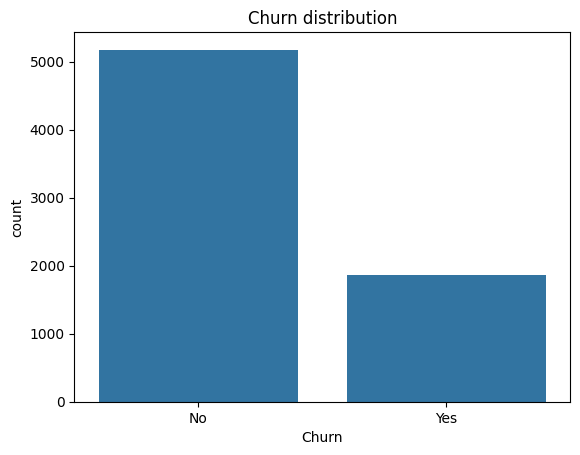

In [5]:
print(df['Churn'].value_counts())
print()
print(df['Churn'].value_counts(normalize=True).round(3))

sns.countplot(x='Churn', data=df)
plt.title('Churn distribution')
plt.show()

The classes are imbalanced (around 73.5% No vs 26.5% Yes), so accuracy alone won't be a good metric. I will also look at recall, F1 and ROC-AUC.

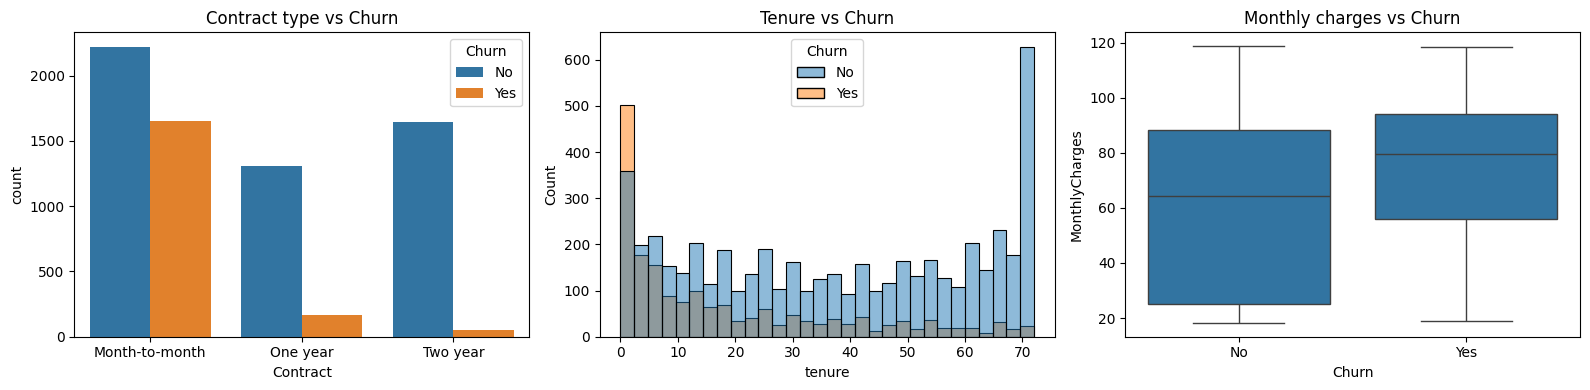

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.countplot(x='Contract', hue='Churn', data=df, ax=axes[0])
axes[0].set_title('Contract type vs Churn')

sns.histplot(data=df, x='tenure', hue='Churn', bins=30, ax=axes[1])
axes[1].set_title('Tenure vs Churn')

sns.boxplot(x='Churn', y='MonthlyCharges', data=df, ax=axes[2])
axes[2].set_title('Monthly charges vs Churn')

plt.tight_layout()
plt.show()

Month-to-month customers, new customers (low tenure) and customers with high monthly charges churn more often.

## 3. Data Preprocessing

In [7]:
# TotalCharges is stored as text and has some blank values
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print('Missing TotalCharges:', df['TotalCharges'].isnull().sum())

# these are customers with tenure 0 who haven't been billed yet
df['TotalCharges'] = df['TotalCharges'].fillna(0)

# customerID is just an identifier
df = df.drop('customerID', axis=1)

df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

Missing TotalCharges: 11


In [8]:
cat_cols = df.select_dtypes(include='object').columns.tolist()
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
print('Categorical columns:', cat_cols)

# binary yes/no style columns become 0/1, the rest get one-hot encoded
binary_cols = [c for c in cat_cols if df[c].nunique() == 2]
multi_cols = [c for c in cat_cols if df[c].nunique() > 2]

for c in binary_cols:
    df[c] = df[c].astype('category').cat.codes

df = pd.get_dummies(df, columns=multi_cols, drop_first=True, dtype=int)
print(df.shape)
df.head()

Categorical columns: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
(7043, 31)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,...,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,0,1,0,1,0,1,29.85,29.85,0,...,0,0,0,0,0,0,0,0,1,0
1,1,0,0,0,34,1,0,56.95,1889.50,0,...,0,0,0,0,0,1,0,0,0,1
2,1,0,0,0,2,1,1,53.85,108.15,1,...,0,0,0,0,0,0,0,0,0,1
3,1,0,0,0,45,0,0,42.30,1840.75,0,...,1,0,0,0,0,1,0,0,0,0
4,0,0,0,0,2,1,1,70.70,151.65,1,...,0,0,0,0,0,0,0,0,1,0


In [9]:
X = df.drop('Churn', axis=1)
y = df['Churn'].values

# 70% train, 15% validation, 15% test
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=42)
X_train, X_val, X_test = X_train.copy(), X_val.copy(), X_test.copy()

# scale only the numeric columns, fit on train data only
scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_val[num_cols] = scaler.transform(X_val[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

X_train = X_train.values.astype('float32')
X_val = X_val.values.astype('float32')
X_test = X_test.values.astype('float32')

print('Train:', X_train.shape, ' Val:', X_val.shape, ' Test:', X_test.shape)

Train: (4930, 30)  Val: (1056, 30)  Test: (1057, 30)


## 4. Model Architecture

In [10]:
def build_model(n_features):
    model = keras.Sequential([
        layers.Input(shape=(n_features,)),
        layers.Dense(64, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.3),
        layers.Dense(32, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.3),
        layers.Dense(16, activation='relu'),
        layers.Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
                  loss='binary_crossentropy',
                  metrics=['accuracy', keras.metrics.AUC(name='auc')])
    return model

model = build_model(X_train.shape[1])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,993 (19.50 KB)

 Trainable params: 4,801 (18.75 KB)

 Non-trainable params: 192 (768.00 B)

## 5. Training

In [11]:
early_stop = keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
reduce_lr = keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-5)

history = model.fit(X_train, y_train,
                    validation_data=(X_val, y_val),
                    epochs=100,
                    batch_size=32,
                    callbacks=[early_stop, reduce_lr],
                    verbose=1)

Epoch 1/100
155/155 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.6970 - auc: 0.7105 - loss: 0.5748 - val_accuracy: 0.7727 - val_auc: 0.8170 - val_loss: 0.4747 - learning_rate: 0.0010
Epoch 2/100
155/155 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7836 - auc: 0.8011 - loss: 0.4621 - val_accuracy: 0.7983 - val_auc: 0.8282 - val_loss: 0.4393 - learning_rate: 0.0010
Epoch 3/100
155/155 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7858 - auc: 0.8164 - loss: 0.4496 - val_accuracy: 0.7936 - val_auc: 0.8338 - val_loss: 0.4308 - learning_rate: 0.0010
Epoch 4/100
155/155 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7905 - auc: 0.8249 - loss: 0.4406 - val_accuracy: 0.8068 - val_auc: 0.8317 - val_loss: 0.4324 - learning_rate: 0.0010
Epoch 5/100
155/155 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7974 - auc: 0.8311 - loss: 0.4338 - val_accuracy: 0.8021 - val_auc: 0.8355 - val_loss: 0.4302 - learning_rate: 0.0010
Epoch 6/100
155/155 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7945 - a

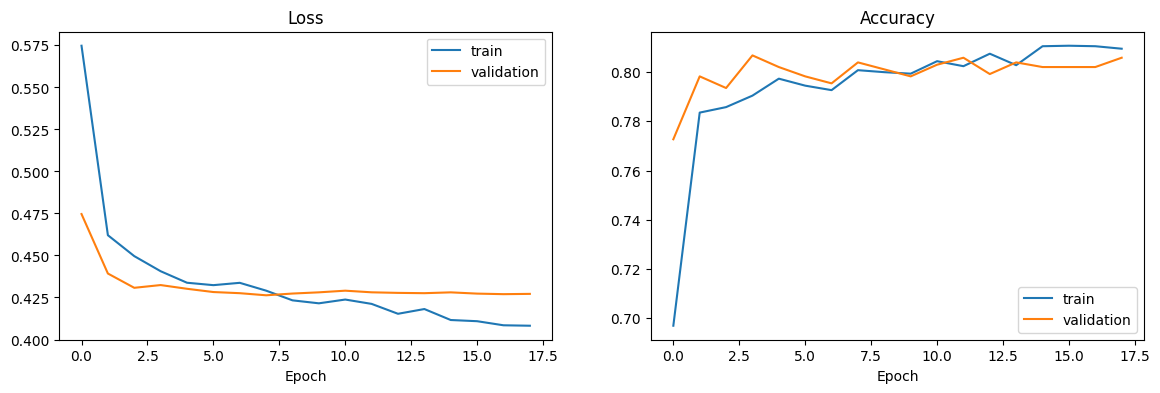

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(history.history['loss'], label='train')
axes[0].plot(history.history['val_loss'], label='validation')
axes[0].set_title('Loss')
axes[0].set_xlabel('Epoch')
axes[0].legend()

axes[1].plot(history.history['accuracy'], label='train')
axes[1].plot(history.history['val_accuracy'], label='validation')
axes[1].set_title('Accuracy')
axes[1].set_xlabel('Epoch')
axes[1].legend()

plt.show()

## 6. Evaluation on the test set

In [13]:
y_prob = model.predict(X_test).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print('Accuracy :', round(accuracy_score(y_test, y_pred), 4))
print('Precision:', round(precision_score(y_test, y_pred), 4))
print('Recall   :', round(recall_score(y_test, y_pred), 4))
print('F1 score :', round(f1_score(y_test, y_pred), 4))
print('ROC-AUC  :', round(roc_auc_score(y_test, y_prob), 4))
print()
print(classification_report(y_test, y_pred, target_names=['No Churn', 'Churn']))

34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
Accuracy : 0.7966
Precision: 0.6618
Recall   : 0.4804
F1 score : 0.5567
ROC-AUC  : 0.837

              precision    recall  f1-score   support

    No Churn       0.83      0.91      0.87       776
       Churn       0.66      0.48      0.56       281

    accuracy                           0.80      1057
   macro avg       0.75      0.70      0.71      1057
weighted avg       0.78      0.80      0.79      1057



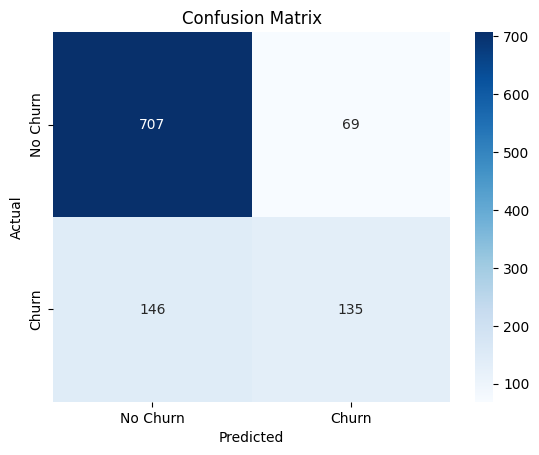

In [14]:
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Churn', 'Churn'], yticklabels=['No Churn', 'Churn'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

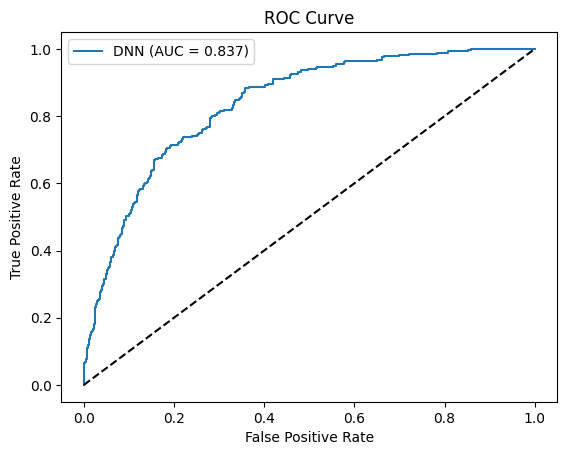

In [15]:
fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.plot(fpr, tpr, label=f'DNN (AUC = {roc_auc_score(y_test, y_prob):.3f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

## 7. Conclusion

The DNN reached about 80% accuracy on the test set. It learned the main churn patterns in the data: customers on month-to-month contracts, customers in their first few months (low tenure) and customers with high monthly charges are the most likely to leave.

**Training behaviour.** The loss and accuracy curves show no overfitting. Validation loss decreased steadily and levelled off after about 60–70 epochs, and the gap between training and validation stayed small (around 80.5% vs 79.5% accuracy). Dropout and Batch Normalization helped keep the model general. The model trained for the full 100 epochs because validation loss kept improving slightly, so early stopping was never triggered.

**Why accuracy is around 80%.** Only about 27% of customers churn, so a model that always predicts "No Churn" would already score about 73%. Validation accuracy started at exactly this baseline, and the network improved on it by about 7 percentage points. Published results on this dataset generally top out around 80–82% accuracy, whatever the model, because customers with identical details often make different choices. So 80% is close to the realistic limit for this data.

**Class weights.** An earlier version used class weights to make the model focus on the minority churn class. That raised recall (more churners caught) but lowered accuracy to about 76%, because more loyal customers were wrongly flagged. The final model was trained without class weights for the better overall accuracy. For a company that cares most about catching every possible churner, the weighted version, or a lower decision threshold, would be a reasonable alternative.

**Future improvements.** The 0.5 decision threshold could be tuned to balance precision and recall for the company's budget. New features, such as average charge per month of tenure, could help, and the results could be compared with simpler models like logistic regression or gradient boosting.